<a href="https://colab.research.google.com/github/eniyigena/ML-Teaching-/blob/main/Python_DecisionTrees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Data Science with Python: Decision Trees**

In this notebook, we will see how to build a decision tree data science algorithm using Python. In particular, we will use the Iris data set to illustrate how to build a decision tree model using the Python sklearn library. Scikit-learn (also known as sklearn) is a free software machine learning library for the Python programming language. It features various classification, regression and clustering algorithms.

Decision Trees (DTs) are a supervised learning method that can be used for classification. The goal is to create a model that predicts the value of a target variable by learning simple decision rules inferred from the data features.


A visual introduction to decision trees: http://www.r2d3.us/visual-intro-to-machine-learning-part-1/

Some advantages of decision trees are:

* Simple to understand and to interpret. Trees can be visualised.
* Requires little data preparation. Other techniques often require data normalisation, dummy variables need to be created and blank values to be removed. Note however that this module does not support missing values.
* The cost of using the tree (i.e., predicting data) is logarithmic in the number of data points used to train the tree.
* Able to handle both numerical and categorical data. Other techniques are usually specialised in analysing datasets that have only one type of variable.
* Able to handle multi-output problems.
* Uses a white box model. If a given situation is observable in a model, the explanation for the condition is easily explained by boolean logic. By contrast, in a black box model (e.g., in an artificial neural network), results may be more difficult to interpret.
* Performs well even if its assumptions are somewhat violated by the true model from which the data were generated.


The disadvantages of decision trees include:
* Decision-tree learners can create over-complex trees that do not generalise the data well. This is called overfitting. [To be continued...]
* Decision trees can be unstable because small variations in the data might result in a completely different tree being generated. This problem can be mitigated. [To be continued...]
* The problem of learning an optimal decision tree is known to be NP-complete under several aspects of optimality and even for simple concepts. Consequently, practical decision-tree learning algorithms are based on heuristic algorithms such as the greedy algorithm where locally optimal decisions are made at each node. Such algorithms cannot guarantee to return the globally optimal decision tree. This can be mitigated. [To be continued...]
* There are concepts that are hard to learn because decision trees do not express them easily, such as XOR (i.e. logical operation that outputs true only when inputs differ (one is true, the other is false).).
* Decision tree learners create biased trees if some classes dominate. It is therefore recommended to balance the dataset prior to fitting with the decision tree. [To be continued...]

# Setup

First, let's make sure this notebook works well in both python 2 and 3, import a few common modules and ensure MatplotLib plots figures inline. Overall, the code below sets up a Python environment tailored for scientific computing and customized plotting.






In [ ]:
# To write a Python 2/3 compatible codebase, the first step is to add this line to the top of each module
from __future__ import division, print_function, unicode_literals

# Two of the main libraries used for scientific computing in Python are imported
# Numpy is the fundamental package for scientific computing with Python.
# SciPy (pronounced "Sigh Pie") is an open source Python library used for scientific computing and technical computing.
import numpy as np # np is an alias pointing to numpy
import scipy as sp # sp is an alias pointing to scipy

# Seed the generator to make this notebook's output stable across runs (the same result every time the code is run, ensuring reproducibility)
np.random.seed(42)

# To plot pretty figures
%matplotlib inline
                                     # matplotlib is a plotting library for the Python programming language
                                     # makes sure that any plots you create are displayed inline in the notebook, below the code cells, instead of in a separate window
import matplotlib                    # the matplotlib library is imported for plotting
import matplotlib.pyplot as plt      # pyplot module is matplotlib's plotting framework https://matplotlib.org/users/pyplot_tutorial.html

# Dynamically change the default rc (runtime configuration) settings in a python script
# See documentation for a complete list of parameters https://matplotlib.org/users/customizing.html
# We change the default rc (runtime configuration) settings (all the plots will have a consistent appearance without having to specify these settings every time)
plt.rcParams['axes.labelsize'] = 14  # fontsize of the x any y labels
plt.rcParams['xtick.labelsize'] = 12 # fontsize of the x tick labels
plt.rcParams['ytick.labelsize'] = 12 # fontsize of the y tick labels

# Training and Visualizing a Decision Tree

To understand Decision Trees, let’s just build one and take a look at how it makes predictions.
The following code trains a DecisionTreeClassifier on the iris dataset.

First, this code focuses on importing the necessary modules, loading the Iris dataset, and performing some initial exploration of the target variable. Then, the code visually inspects the Iris dataset by plotting the petal dimensions in a scatter plot, the petal dimensions in histograms, and printing the descriptive statistics for petal dimensions. Lastly, this code initializes and trains a Decision Tree classifier on the entire Iris dataset.






The frequency of instances per class is:  {np.int64(0): np.int64(50), np.int64(1): np.int64(50), np.int64(2): np.int64(50)}
The names of the three distinct classes are:  [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Petal length statistics:  DescribeResult(nobs=np.int64(150), minmax=(np.float64(1.0), np.float64(6.9)), mean=np.float64(3.7580000000000005), variance=np.float64(3.1162778523489933), skewness=np.float64(-0.2721276664567214), kurtosis=np.float64(-1.3955358863990055))
Petal width statistics:  DescribeResult(nobs=np.int64(150), minmax=(np.float64(0.1), np.float64(2.5)), mean=np.float64(1.1993333333333336), variance=np.float64(0.5810062639821029), skewness=np.float64(-0.10193420656560036), kurtosis=np.float64(-1.336067405231553))


DecisionTreeClassifier(max_depth=2, random_state=42)

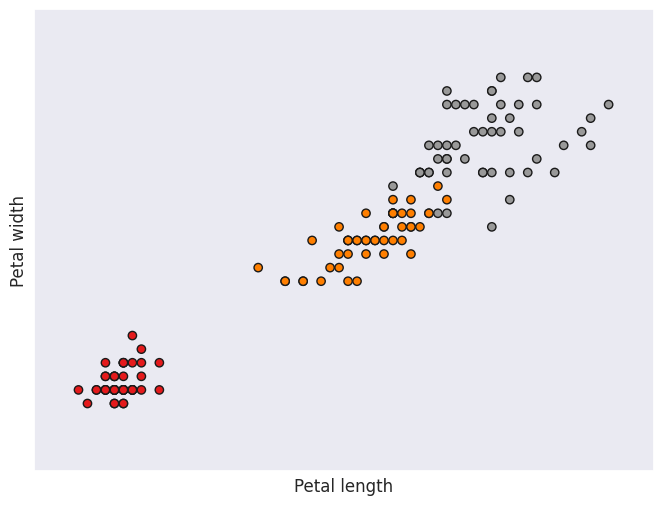

<Figure size 800x600 with 0 Axes>

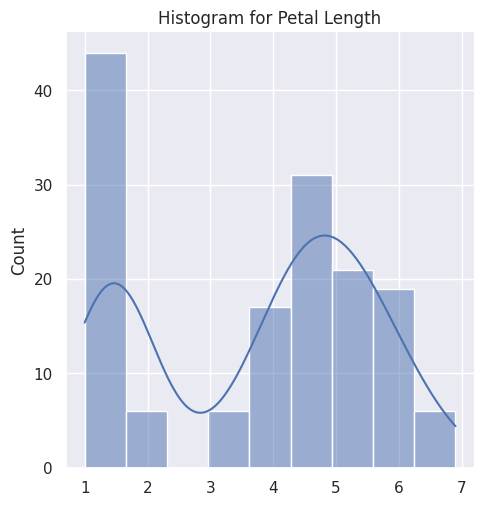

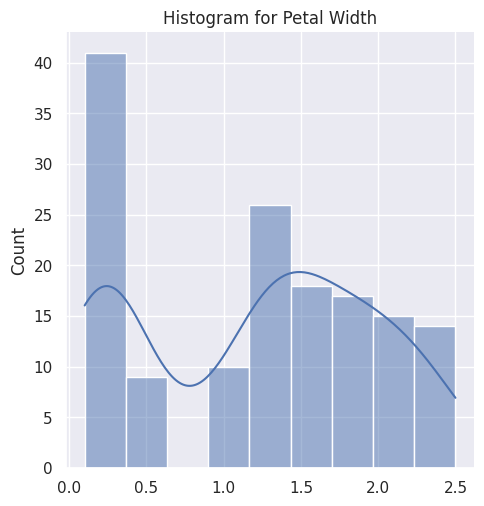

In [ ]:
########################################### Imports ###########################################

# The function load_iris from sklearn.datasets is used to load the Iris dataset
from sklearn.datasets import load_iris # sklearn is a machine learning library for the Python

# Iris Dataset:
# Learn more about the iris dataset here https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
# 3 class outcome: Iris-Setosa, Iris-Versicolour, and Iris-Virginica
# 4 numeric attribuets: sepal length in cm, sepal width in cm, petal length in cm, petal width in cm

# A decision tree classifier is imported from sklearn.tree
from sklearn.tree import DecisionTreeClassifier # The sklearn.tree module includes decision tree-based models for
                                                # classification
# Documentation for decision Tree Classifier
# http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

# Seaborn is a Python data visualization library based on matplotlib.
# Seaborn documentation can be found here https://seaborn.pydata.org/generated/seaborn.set.html
import seaborn as sns     # sns is an alias pointing to seaborn
sns.set(color_codes=True) # Set aesthetic parameters in one step (configures the color palette). Remaps the shorthand color codes (e.g. “b”, “g”, “r”, etc.)
                          # to the colors from this palette.
from scipy import stats   # Documentation stats package of scipy https://docs.scipy.org/doc/scipy/reference/stats.html#module-scipy.stats
                          # stats is seful for statistical functions

######################################### Data Exploration #########################################

#Load Iris Dataset. Learn more about the dataset here https://en.wikipedia.org/wiki/Iris_flower_data_set
iris = load_iris()

# Retrieving Attributes
X = iris.data[:, 2:]     # keep specific attributes (i.e., third column and beyond); keep petal length and width
# Retriving Target Variable
y = iris.target

# Exploring Target Variable
# np.unique finds the unique elements of an array and returns their counts
unique, counts = np.unique(y, return_counts=True) # 3 distinct classes equally represented
print("The frequency of instances per class is: " , dict(zip(unique, counts)))  # zip pairs the unique labels with the corresponding counts
                                                                                # this is converted to a dictionary to present the frequencies for each class.
print("The names of the three distinct classes are: ", list(iris.target_names)) # displays a list of the target variable names
#print(iris.data[1:5,:])

######################################### Visualizations #########################################

# Visual inspection of dataset
# Plot the training points

# Setting plot limits
# These lines determine the plotting boundaries for the x-axis (based on the first column of X, which represents the petal length)
# and y-axis (based on the second column of X, which represents the petal width). A margin of 0.5 units is added/subtracted to/from
# the minimum/maximum values for better visualization.
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5 # estimate x axis limits based on dataset
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5 # estimate y axis limits based on dataset

# A scatter plot is created to visualize the petal dimensions
plt.figure(2, figsize=(8, 6)) # Set dimensions of new figure and figure id https://matplotlib.org/api/_as_gen/matplotlib.pyplot.figure.html
                              # Initializes a new figure with ID 2 and size 8x6 inches.
plt.clf()                     # Clear the current figure (so that no previous plots interfere with this one)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1, # creates a scatter plot
            edgecolor='k') # c, cmap, and edgecolor are parameters for color
                           # The color c=y indicates that the colors of the dots will be determined by the target values y
                           # cmap specifies the color map
                           # edgecolor defines the color of the dot edges
                           # see scatter documentation here https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.scatter.html
plt.xlabel('Petal length') # x label name
plt.ylabel('Petal width')  # y label name

plt.xlim(x_min, x_max) # set x axis limits
plt.ylim(y_min, y_max) # set y axis limits
plt.xticks(())
plt.yticks(())         # these lines remove the tick marks from both axes

# Histograms are created to visualize petal dimensions
plt.figure(3, figsize=(8, 6)) # initializes another figure (ID 3)
# Plots two histograms using Seaborn's displot function with feature indication
sns.displot(iris.data[:, 2], kde=True).set(title='Histogram for Petal Length')  # histogram plot for petal length
sns.displot(iris.data[:, 3], kde=True).set(title='Histogram for Petal Width')   # histogram plot for petal width

# Descriptive statistics for the petal length and petal width
print("Petal length statistics: ", sp.stats.describe(iris.data[:,2])) # sp.stats.describe function computes several descriptive statistics
                                                                      # (mean, variance, skewness, etc) of the passed array
print("Petal width statistics: ", sp.stats.describe(iris.data[:,3]))

######################################### Model Training #########################################


# The following code trains a DecisionTreeClassifier on the iris dataset
# Decision Tree Induction (Fitting the Model)
# Documentation https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

# Create an instance of the DecisionTreeClassifier from the scikit-learn library
tree_clf = DecisionTreeClassifier(max_depth=2,     # restricts the tree's maximum depth to 2
                                  random_state=42) # this is a seed for the random number generator
                                                   # be aware of default parameters e.g., default criterion is gini
# Train (fit) the classifier to the data
tree_clf.fit(X, y)

# Please see next block of code for *splitting the data* into train and test sets in order to evaluate the generalization performance of the model.


The following code snippet helps us visualize the decision tree that has been trained on the Iris dataset. Visualization is crucial in machine learning, especially for decision trees, as it helps in understanding the decision-making process of the model.

Decision Tree Visualization


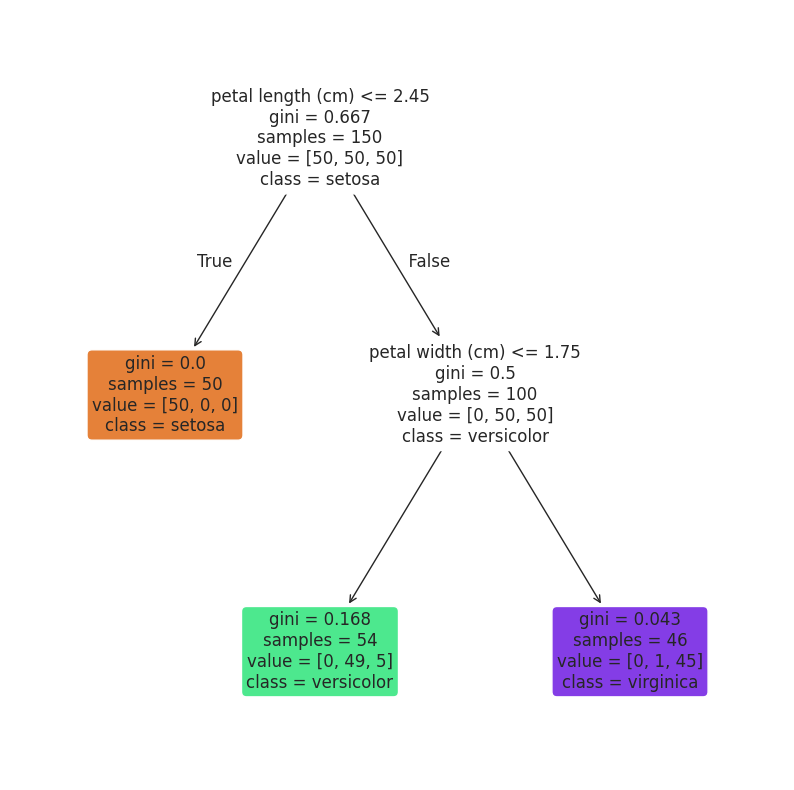

In [ ]:
######################################### Visualization of the Decision Tree #########################################

# Imports the tree module from the scikit-learn library
from sklearn import tree

plt.figure(figsize=(10,10)) # initializes a new figure where the tree will be plotted (size 10x10 inches)

# Visualizing the Tree
# plot_tree function from the tree module plots a decision tree; see documentation https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html
tree.plot_tree(tree_clf.fit(X, y),                        # the decision tree to be plotted
                                                          # tree_clf.fit(X, y) returns the trained model
               feature_names = iris.feature_names[2:],    # names of each of the features. If None, generic names will be used (“X[0]”, “X[1]”, …)
                                                          # extracts the names of the features starting from the third feature onward; this matches our previous use of X = iris.data[:, 2:]
               filled = True,                             # when set to True, color nodes to indicate majority class for classification,
                                                          # or purity of node for multi-output.
               class_names = iris.target_names,           # names of each of the target classes in ascending numerical order.
               rounded = True,                            # when set to True, draw node boxes with rounded corners and use Helvetica fonts instead of Times-Roman.
               fontsize=12)                               # size of text font. If None, determined automatically to fit figure.

# Print the string 'Decision Tree Visualization' to the console
print('Decision Tree Visualization')


Lets see how the tree represented the previous figure makes predictions. Suppose you find
an iris flower and you want to classify it. You start at the root node (depth 0, at the
top): this node asks whether the flower’s petal length is smaller than 2.45 cm. If it is,
then you move down to the root’s left child node (depth 1, left). In this case, it is a leaf
node (i.e., it does not have any children nodes), so it does not ask any questions: you
can simply look at the predicted class for that node and the Decision Tree predicts
that your flower is an Iris-Setosa (class=setosa).

Now suppose you find another flower, but this time the petal length is greater than
2.45 cm. You must move down to the root’s right child node (depth 1, right), which is
not a leaf node, so it asks another question: is the petal width smaller than 1.75 cm? If
it is, then your flower is most likely an Iris-Versicolor (depth 2, left). If not, it is likely
an Iris-Virginica (depth 2, right).

A node’s samples attribute counts how many training instances it applies to. For
example, 100 training instances have a petal length greater than 2.45 cm (depth 1,
right), among which 54 have a petal width smaller than 1.75 cm (depth 2, left). A
node’s value attribute tells you how many training instances of each class this node
applies to: for example, the bottom-right node applies to 0 Iris-Setosa, 1 Iris-
Versicolor, and 45 Iris-Virginica. Finally, a node’s gini attribute measures its impurity:
a node is “pure” (gini=0) if all training instances it applies to belong to the same
class. For example, since the depth-1 left node applies only to Iris-Setosa training
instances, it is pure and its gini score is 0.

Note: Scikit-Learn uses the CART algorithm, which produces only binary
trees: nonleaf nodes always have two children (i.e., questions only
have yes/no answers). However, other algorithms such as ID3 can
produce Decision Trees with nodes that have more than two children.

# Model Evaluation

The following code goes through multiple phases: importing necessary modules, splitting the dataset, training a decision tree model, visualizing the decision tree, and then visualizing the performance of the trained model using confusion matrices.

Decision Tree Visualization


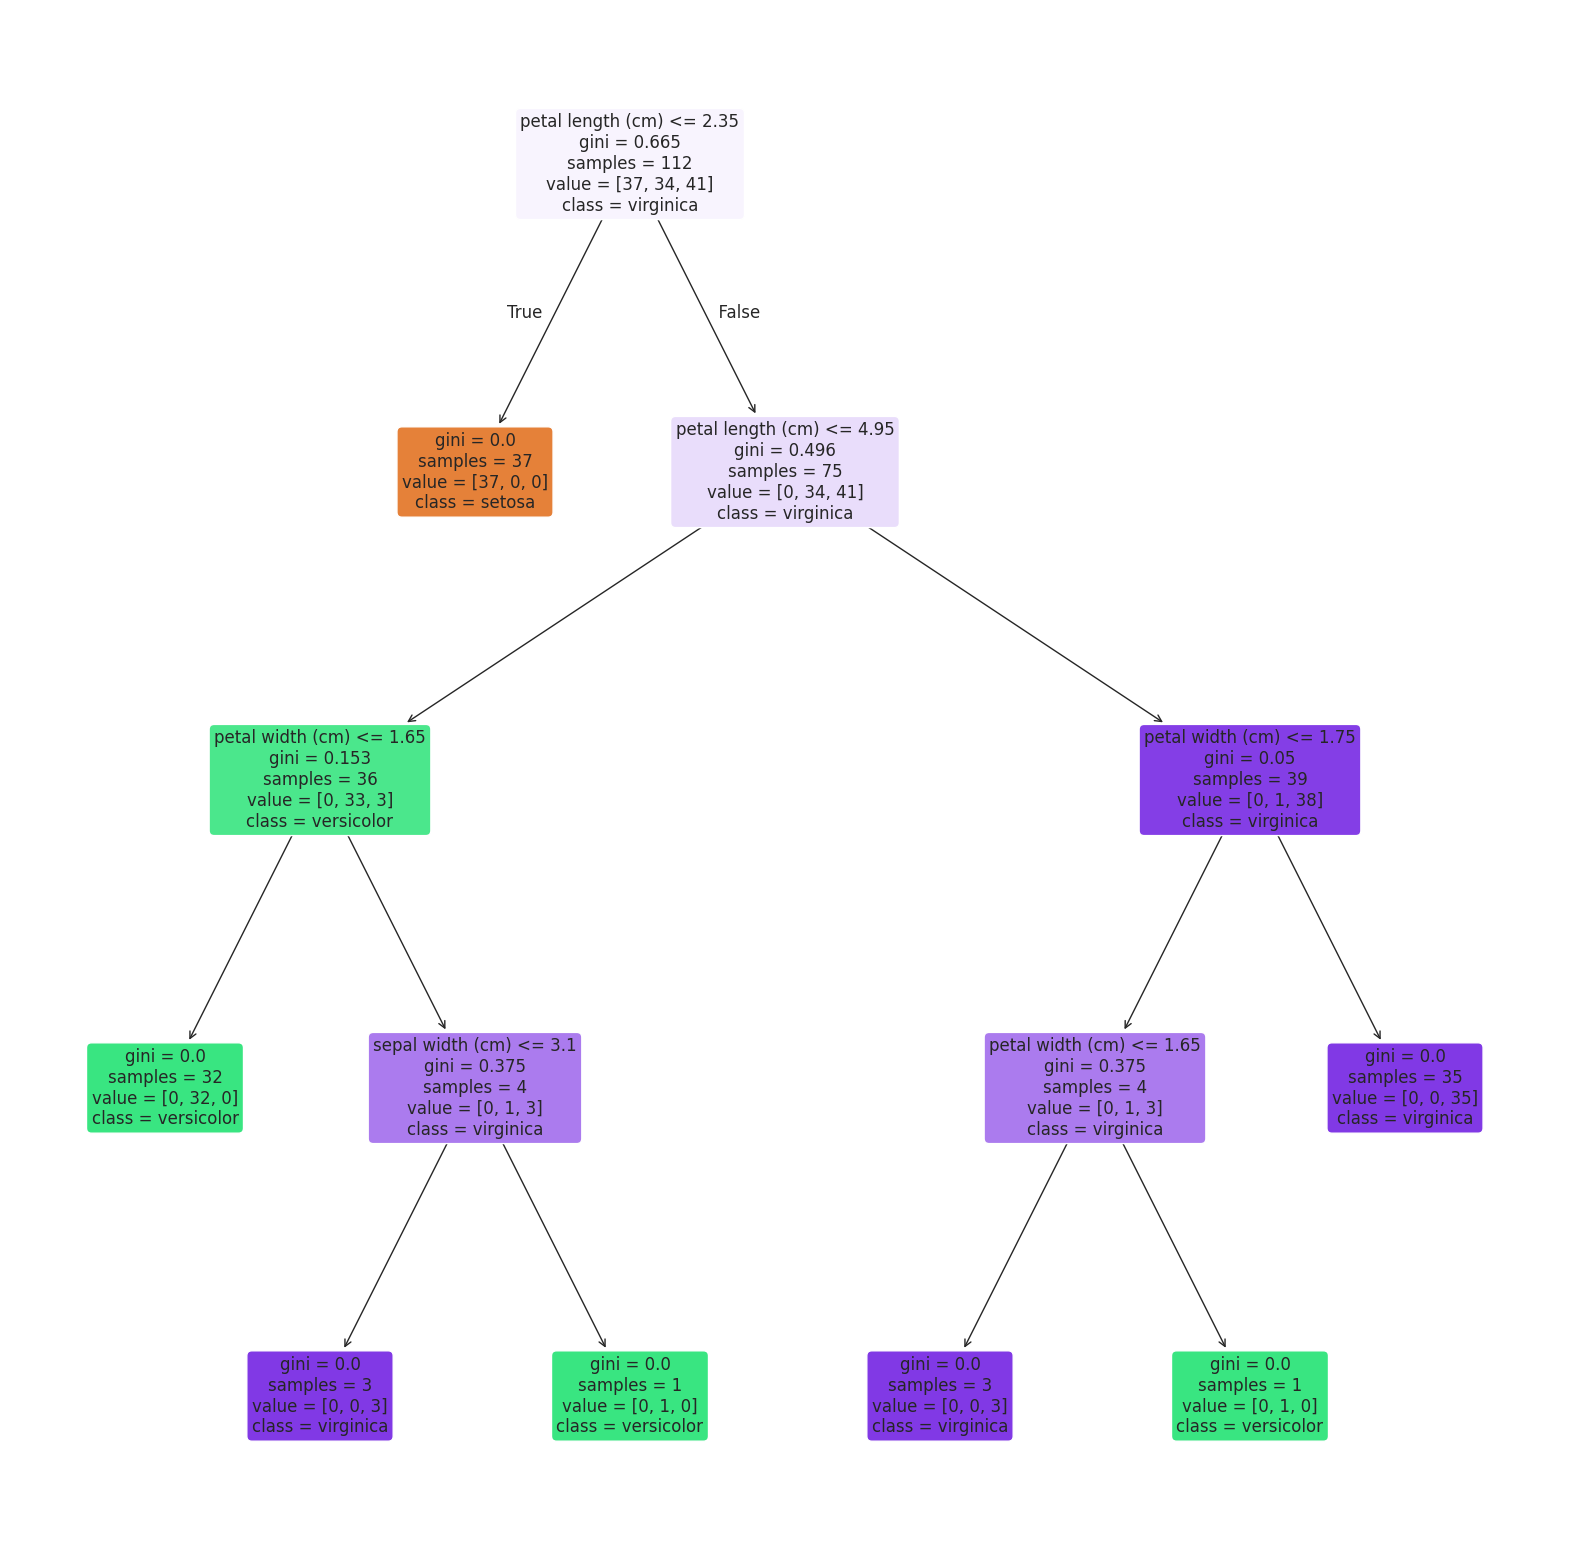

Confusion matrix, without normalization
[[13  0  0]
 [ 0 15  1]
 [ 0  0  9]]
Normalized confusion matrix
[[1.   0.   0.  ]
 [0.   0.94 0.06]
 [0.   0.   1.  ]]


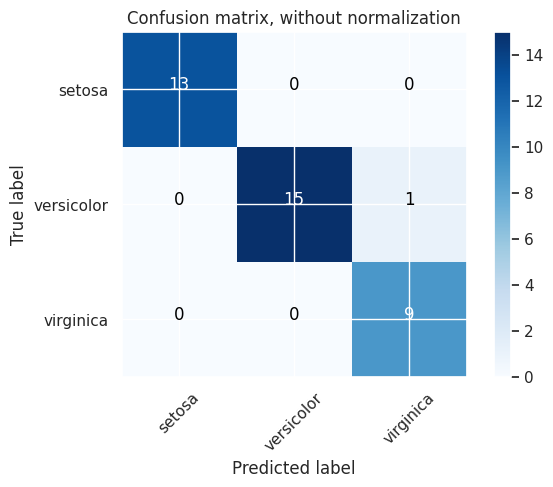

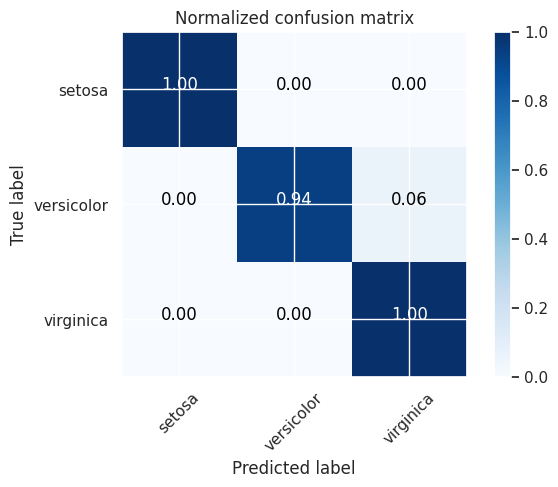

In [ ]:
######################################### Imports #########################################
from sklearn.metrics import confusion_matrix           # confusion_matrix will help us compute confusion matrix
import itertools                                       # python’s Itertool is a module that provides various functions that work on iterators
from sklearn.model_selection import train_test_split   # randomly splits arrays or matrices into random train and test subsets.


###################################### Split the Data ######################################

# Split the data into a training set and a test set
X_train, X_test, y_train, y_test = train_test_split(iris.data,        # dataset to be split
                                                    iris.target,      # dataset to be split (all specified inputs to be split should have the same length)
                                                    random_state=0)   # controls the shuffling for reproducible output
# Note: It is typically a good idea to shuffle the dataset before you split it into training and testing
# train_test_split performs shuffling by default

############################# Build Model & Apply it to the Test Set #######################

# Build the decision tree model

# Initialize classifier
clf3 = tree.DecisionTreeClassifier() # uses defacult parameter values e.g., gini criterion, None max-depth, etc.
                                     # please see the sklearn documentation for details
                                     # https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

# Fit the classifier to the data
# "clf3.fit(X_train, y_train)"" fits the model and then
# ".predict(X_test)" makes predicitions based on the test set
y_pred = clf3.fit(X_train, y_train).predict(X_test) # predict the labels of the test data


############################## Visualization of the Decision Tree ############################

# Import required modules for visualization
import matplotlib.pyplot as plt
from sklearn import tree

plt.figure(figsize=(20,20))                        # initializes a new figure where the tree will be plotted (size 10x10 inches)
tree.plot_tree(clf3.fit(X_train, y_train),         # the decision tree to be plotted
               feature_names = iris.feature_names, # names of each of the features. If None, generic names will be used (“X[0]”, “X[1]”, …).
               filled = True,                      # when set to True, paint nodes to indicate majority class for classification,
                                                   # or purity of node for multi-output.
               class_names = iris.target_names,    # names of each of the target classes in ascending numerical order.
               rounded = True,                     # when set to True, draw node boxes with rounded corners and use Helvetica fonts instead of Times-Roman.
               fontsize=12)                        # size of text font. If None, determined automatically to fit figure.

# Print the string 'Decision Tree Visualization' to the console
print('Decision Tree Visualization')
plt.show()

###################################### Confusion Matrix #####################################


# Function that prints and plots the confusion matrix.
# The function provides options to display the matrix as raw counts or normalized values (percentages)
# This function uses matplotlib's functionalities to create a heat map of the confusion matrix and then annotate it with values.
# Normalization can be applied by setting `normalize=True` (see below for examples)
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # devide absolute number of observations with sum across columns to get the relative percentage of observations
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)         # shows the confusion matrix in the console
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))                       # add tick marks to the confusion matrix
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'                          # choose format depending on whether the confusion matrix is normalized or not
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])): # loop that adds the value to each cell of the confusion matrix
        plt.text(j, i, format(cm[i, j], fmt),                              # we reformat how the cell values are displayed accroding to the variable fmt we defined before
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Compute confusion matrix to evaluate the accuracy of a classification
cnf_matrix = confusion_matrix(y_test, y_pred)
#Determine the way floating point numbers are displayed
np.set_printoptions(precision=2)                              # number of digits of precision for floating point output

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix,
                      classes=iris.target_names,
                      title='Confusion matrix, without normalization')

# Plot normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix,
                      classes=iris.target_names,
                      normalize=True,
                      title='Normalized confusion matrix')

plt.show()


# Predicting the Classes

In [ ]:
#All supervised estimators in scikit-learn implement a fit(X, y) method to fit the model and
#a predict(X) method that, given unlabeled observations X, returns the predicted labels y.

tree_clf.predict([[5, 1.5]]) # Make predictions based on fitted model

array([1])

# Estimating the Class Probabilities

A Decision Tree can also estimate the probability that an instance belongs to a particular
class k. [To be continued...]

In [ ]:
tree_clf.predict_proba([[5, 1.5]]) # Make class probability predictions based on fitted model

array([[0.  , 0.91, 0.09]])

# The CART Training Algorithm

Scikit-Learn uses the Classification And Regression Tree (CART) algorithm to train
Decision Trees (also called “growing” trees). The idea is really quite simple: the algorithm
first splits the training set in two subsets using a single feature $k$ and a threshold
$t_k$ (e.g., “petal length ≤ 2.45 cm”). How does it choose $k$ and $t_k$? It searches for the
pair ($k$, $t_k$) that produces the purest subsets (weighted by their size). The cost function
that the algorithm tries to minimize is given by the following equation:

$$ J(k,t_k) = \frac{m_{left}}{m} G_{left} + \frac{m_{right}}{m} G_{right}, $$

\begin{equation}
  where \begin{cases}
    G_{\text{ left / right}} \text{ measures the impurity of the left/right subset}, \\
    m_{\text{ left / right}} \text{ is the number of instances in the left/right subset}. \\
  \end{cases}
\end{equation}


Once it has successfully split the training set in two, it splits the subsets using the
same logic, then the sub-subsets and so on, recursively. It stops recursing once it reaches
the maximum depth (defined by the max_depth hyperparameter), or if it cannot
find a split that will reduce impurity. A few other hyperparameters (described in a moment) control additional stopping conditions (e.g., min_samples_split, min_samples_leaf, etc).


The CART algorithm is a greedy algorithm: it greedily
searches for an optimum split at the top level, then repeats the
process at each level. It does not check whether or not the split will
lead to the lowest possible impurity several levels down. A greedy
algorithm often produces a reasonably good solution, but it is not
guaranteed to be the optimal solution.

Unfortunately, finding the optimal tree is known to be an NP-Complete problem: it
requires O(exp(m)) time, making the problem intractable even for fairly small training
sets. This is why we must settle for a “reasonably good” solution.

Note: P is the set of problems that can be solved in polynomial time. NP is the set of problems whose solutions can
be verified in polynomial time. An NP-Hard problem is a problem to which any NP problem can be reduced
in polynomial time. An NP-Complete problem is both NP and NP-Hard. A major open mathematical question
is whether or not P = NP. If P ≠ NP (which seems likely), then no polynomial algorithm will ever be
found for any NP-Complete problem.


# Computational Complexity

Making predictions requires traversing the Decision Tree from the root to a leaf.
Decision Trees are generally approximately balanced, so traversing the Decision Tree
requires going through roughly $O(log_2(m))$ nodes. Since each node only requires
checking the value of one feature, the overall prediction complexity is just $O(log_2(m))$,
independent of the number of features. So predictions are very fast, even when dealing
with large training sets.

However, the training algorithm compares all features (or less if max_features is set)
on all samples at each node. This results in a training complexity of O(n × m log(m)).
For small training sets (less than a few thousand instances), Scikit-Learn can speed up
training by presorting the data (set presort=True), but this slows down training considerably
for larger training sets.

# Choosing Information Criterion: Gini Impurity or Entropy?


By default, the Gini impurity measure is used, but you can select the entropy impurity
measure instead by setting the criterion hyperparameter to "entropy". The concept
of entropy originated in thermodynamics as a measure of molecular disorder:
entropy approaches zero when molecules are still and well ordered. It later spread to a
wide variety of domains, including Shannon’s information theory, where it measures the average information content of a message: entropy is zero when all messages are
identical. In Machine Learning, it is frequently used as an impurity measure: a set’s
entropy is zero when it contains instances of only one class.

As previously discussed in the class, the definition of the entropy of the $i_{th}$ node is:

$$ Entropy_i = - \sum_{k=1}^{n} p_{i,k}log(p_{i,k}) $$

So should we use Gini impurity or entropy? The truth is, most of the time it does not
make a big difference: they lead to similar trees. **Gini impurity is slightly faster** to
compute, so it is a good default. However, when they differ, Gini impurity tends to
isolate the most frequent class in its own branch of the tree, while entropy tends to
produce slightly more balanced trees.

In [ ]:
from matplotlib.colors import ListedColormap

def plot_decision_boundary(clf, X, y, axes=[0, 7.5, 0, 3], iris=True, legend=False, plot_training=True):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)
    custom_cmap = ListedColormap(['#fafab0','#9898ff','#a0faa0'])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)
    if not iris:
        custom_cmap2 = ListedColormap(['#7d7d58','#4c4c7f','#507d50'])
        plt.contour(x1, x2, y_pred, cmap=custom_cmap2, alpha=0.8)
    if plot_training:
        plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris-Setosa")
        plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris-Versicolor")
        plt.plot(X[:, 0][y==2], X[:, 1][y==2], "g^", label="Iris-Virginica")
        plt.axis(axes)
    if iris:
        plt.xlabel("Petal length", fontsize=14)
        plt.ylabel("Petal width", fontsize=14)
    else:
        plt.xlabel(r"$x_1$", fontsize=18)
        plt.ylabel(r"$x_2$", fontsize=18, rotation=0)
    if legend:
        plt.legend(loc="lower right", fontsize=14)

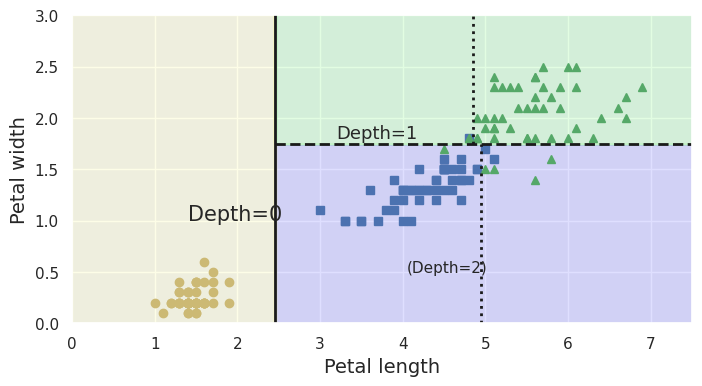

In [ ]:
from google.colab import files

plt.figure(figsize=(8, 4))
plot_decision_boundary(tree_clf, X, y)
plt.plot([2.45, 2.45], [0, 3], "k-", linewidth=2)
plt.plot([2.45, 7.5], [1.75, 1.75], "k--", linewidth=2)
plt.plot([4.95, 4.95], [0, 1.75], "k:", linewidth=2)
plt.plot([4.85, 4.85], [1.75, 3], "k:", linewidth=2)
plt.text(1.40, 1.0, "Depth=0", fontsize=15)
plt.text(3.2, 1.80, "Depth=1", fontsize=13)
plt.text(4.05, 0.5, "(Depth=2)", fontsize=11)

plt.savefig("decision_tree_decision_boundaries_plot")
plt.show()

The previous figure shows this Decision Tree’s decision boundaries. The thick vertical line represents
the decision boundary of the root node (depth 0): petal length = 2.45 cm.
Since the left area is pure (only Iris-Setosa), it cannot be split any further. However,
the right area is impure, so the depth-1 right node splits it at petal width = 1.75 cm
(represented by the dashed line). Since max_depth was set to 2, the Decision Tree
stops right there. However, if you set max_depth to 3, then the two depth-2 nodes
would each add another decision boundary (represented by the dotted lines).

# Hyperparameter Tuning


Decision Trees make very few assumptions about the training data (as opposed to linear models for example).

If left
unconstrained, the tree structure will adapt itself to the training data, fitting it very
closely, and most likely overfitting it. Such a model is often called a nonparametric
model, not because it does not have any parameters (it often has a lot) but because the
number of parameters is not determined prior to training, so the model structure is
free to stick closely to the data. In contrast, a parametric model such as a linear model
has a predetermined number of parameters, so its degree of freedom is limited,
reducing the risk of overfitting (but increasing the risk of underfitting).

To avoid overfitting the training data, you need to restrict the Decision Tree’s freedom
during training. As you know by now, this is called hyperparameter tuning.
[To be continued...]

# Sensitivity to training set details

Hopefully by now you are convinced that Decision Trees have a lot going for them:
they are simple to understand and interpret, easy to use, versatile, and powerful.


However they do have a few limitations. First, as you may have noticed, Decision
Trees love orthogonal decision boundaries (all splits are perpendicular to an axis),
which makes them sensitive to training set rotation. For example, Figure "sensitivity to rotation" shows a
simple linearly separable dataset: on the left, a Decision Tree can split it easily, while
on the right, after the dataset is rotated by 45°, the decision boundary looks unnecessarily
convoluted. Although both Decision Trees fit the training set perfectly, it is very
likely that the model on the right will not generalize well. One way to limit this problem
is to use PCA [To be continued...], which often results in a better orientation of the
training data.

More generally, the main issue with Decision Trees is that they are very sensitive to
small variations in the training data. For example, if you just remove the widest Iris-
Versicolor from the iris training set (the one with petals 4.8 cm long and 1.8 cm wide)
and train a new Decision Tree, you may get the model represented in the following Figure. As
you can see, it looks very different from the previous Decision Tree.
Actually, since the training algorithm used by Scikit-Learn is stochastic (i.e., it randomly selects the set of features to evaluate at each node.) you may
get very different models even on the same training data (unless you set the
random_state hyperparameter).

In [ ]:
X[(X[:, 1]==X[:, 1][y==1].max()) & (y==1)] # widest Iris-Versicolor flower

array([[4.8, 1.8]])

In [ ]:
not_widest_versicolor = (X[:, 1]!=1.8) | (y==2)
X_tweaked = X[not_widest_versicolor]
y_tweaked = y[not_widest_versicolor]

tree_clf_tweaked = DecisionTreeClassifier(max_depth=2, random_state=40)
tree_clf_tweaked.fit(X_tweaked, y_tweaked)

DecisionTreeClassifier(max_depth=2, random_state=40)

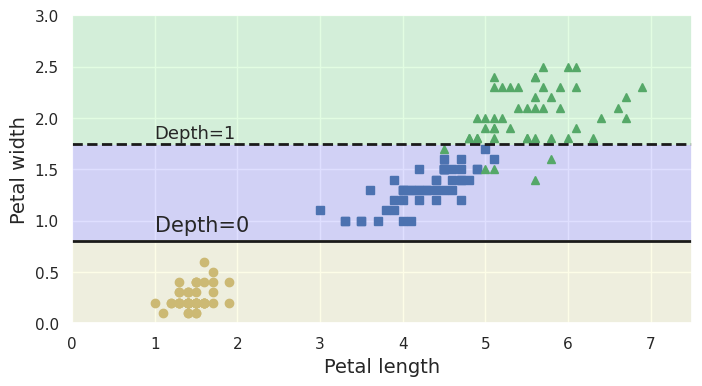

In [ ]:
plt.figure(figsize=(8, 4))
plot_decision_boundary(tree_clf_tweaked, X_tweaked, y_tweaked, legend=False)
plt.plot([0, 7.5], [0.8, 0.8], "k-", linewidth=2)
plt.plot([0, 7.5], [1.75, 1.75], "k--", linewidth=2)
plt.text(1.0, 0.9, "Depth=0", fontsize=15)
plt.text(1.0, 1.80, "Depth=1", fontsize=13)

plt.savefig("decision_tree_instability_plot")
plt.show()

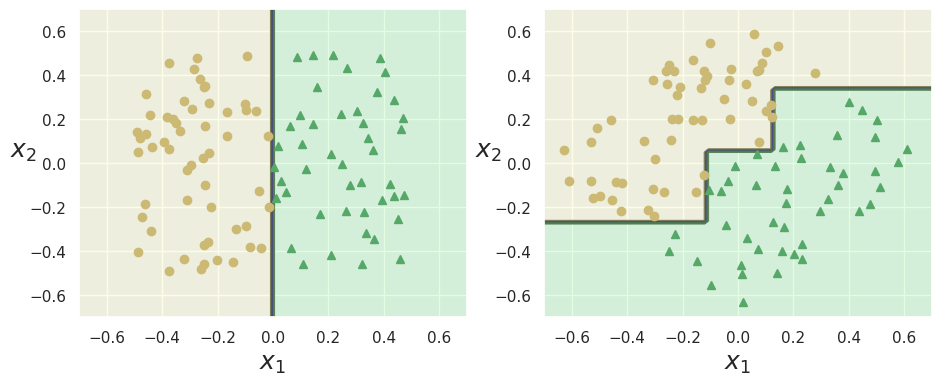

In [ ]:
np.random.seed(6)
Xs = np.random.rand(100, 2) - 0.5
ys = (Xs[:, 0] > 0).astype(np.float32) * 2

angle = np.pi / 4
rotation_matrix = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
Xsr = Xs.dot(rotation_matrix)

tree_clf_s = DecisionTreeClassifier(random_state=42)
tree_clf_s.fit(Xs, ys)
tree_clf_sr = DecisionTreeClassifier(random_state=42)
tree_clf_sr.fit(Xsr, ys)

plt.figure(figsize=(11, 4))
plt.subplot(121)
plot_decision_boundary(tree_clf_s, Xs, ys, axes=[-0.7, 0.7, -0.7, 0.7], iris=False)
plt.subplot(122)
plot_decision_boundary(tree_clf_sr, Xsr, ys, axes=[-0.7, 0.7, -0.7, 0.7], iris=False)

plt.savefig("sensitivity_to_rotation_plot")
plt.show()